# Facial Emotion Detection

The purpose this project is to train a deep learning model to detect the emotion on a person facial. This project was done out of curiosty on how well can deep learning models detect emotions. I will be using FER2013 dataset which is available on kaggle.

# 1. Load libraries for image processing

In [1]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator

# 2.Load Dataset and Data Augmentation

In [2]:
NUM_OF_CLASSESS= 7
BATCH_SIZE=32


train_gen= ImageDataGenerator(
    rescale=1.0 / 255,
    rotation_range=15,
    width_shift_range=0.1,
    height_shift_range=0.1,
    zoom_range=0.1,
    horizontal_flip=True,
    validation_split=0.2
)

test_gen = ImageDataGenerator(
    rescale=1.0 / 255
)

train = train_gen.flow_from_directory(
    "../dataset/train",
    target_size=(48,48),
    color_mode="grayscale",
    class_mode="categorical",
    batch_size=BATCH_SIZE
)

test = test_gen.flow_from_directory(
    "../dataset/test",
    target_size=(48,48),
    color_mode="grayscale",
    class_mode="categorical",
    batch_size=BATCH_SIZE,
    shuffle=False
)


Found 28709 images belonging to 7 classes.
Found 7178 images belonging to 7 classes.


In [3]:
import os

train_path = "../dataset/train"
test_path = "../dataset/test"

print("TRAINING SET")
for emotion in sorted(os.listdir(train_path)):
    folder = os.path.join(train_path, emotion)
    if os.path.isdir(folder):
        count = len([
            f for f in os.listdir(folder)
            if f.lower().endswith(('.jpg', '.jpeg', '.png'))
        ])
        print(f"{emotion}: {count}")

print("\nTEST SET")
for emotion in sorted(os.listdir(test_path)):
    folder = os.path.join(test_path, emotion)
    if os.path.isdir(folder):
        count = len([
            f for f in os.listdir(folder)
            if f.lower().endswith(('.jpg', '.jpeg', '.png'))
        ])
        print(f"{emotion}: {count}")

TRAINING SET
angry: 3995
disgust: 436
fear: 4097
happy: 7215
neutral: 4965
sad: 4830
surprise: 3171

TEST SET
angry: 958
disgust: 111
fear: 1024
happy: 1774
neutral: 1233
sad: 1247
surprise: 831


# 3. CNN Model 



In [4]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.regularizers import L2
from tensorflow.keras.layers import (
    Input,
    RandomFlip,
    RandomRotation,
    RandomZoom,
    RandomContrast,
    Conv2D,
    MaxPooling2D,
    BatchNormalization,
    GlobalAveragePooling2D,
    Dense,
    Dropout,
)


l2_reg = 1e-4 # this is to prebent overfitting in the model

# CNN Model
model = Sequential()

# Use Input layer first to set dimensions (48x48, 1 channel)
model.add(Input(shape=(48, 48, 1)))
model = Sequential([
    Input(shape=(48, 48, 1)),

    # Image Preprocessing
    # data_augmentation,
    
    # Block 1
    Conv2D(32, (3,3), padding='same', activation='relu'),
    BatchNormalization(),
    Conv2D(32, (3,3), padding='same', activation='relu'),
    BatchNormalization(),
    MaxPooling2D((2,2)),
    Dropout(0.20),

    # Block 2
    Conv2D(64, (3,3), padding='same', activation='relu'),
    BatchNormalization(),
    Conv2D(64, (3,3), padding='same', activation='relu'),
    BatchNormalization(),
    MaxPooling2D((2,2)),
    Dropout(0.25),

    # Block 3
    Conv2D(128, (3,3), padding='same', activation='relu'),
    BatchNormalization(),
    Conv2D(128, (3,3), padding='same', activation='relu'),
    BatchNormalization(),
    MaxPooling2D((2,2)),
    Dropout(0.30),

    # Block 4
    Conv2D(256, (3,3), padding='same', activation='relu'),
    BatchNormalization(),
    MaxPooling2D((2,2)),
    Dropout(0.30),

    # Blobal Representation & Head
    GlobalAveragePooling2D(),
    Dense(256, activation='relu', kernel_regularizer=L2(l2_reg)),
    Dropout(0.40),
    Dense(NUM_OF_CLASSESS, activation='softmax')
])

model.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 48, 48, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 48, 48, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 48, 48, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 48, 48, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 24, 24, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 24, 24, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 24, 24, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 24, 24, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 24, 24, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 24, 24, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 12, 12, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 12, 12, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 12, 12, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 12, 12, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 12, 12, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 12, 12, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 6, 6, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 6, 6, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 6, 6, 256)      │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_6           │ (None, 6, 6, 256)      │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 3, 3, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼─────────────

 Total params: 652,007 (2.49 MB)

 Trainable params: 650,599 (2.48 MB)

 Non-trainable params: 1,408 (5.50 KB)

# 4. Train the Model

In [5]:
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

optimizer = Adam(learning_rate=0.0001)
model.compile(
    optimizer=optimizer,
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

early_stopping = EarlyStopping(
    monitor='val_loss', 
    patience=10, 
    restore_best_weights=True,
    verbose=1
)

reduce_lr = ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.5,
    patience=3,
    min_lr=1e-6,
    verbose=1
)

history = model.fit(
    train,
    validation_data=test,
    epochs=50,
    callbacks=[early_stopping, reduce_lr]
)

Epoch 1/50
898/898 ━━━━━━━━━━━━━━━━━━━━ 173s 186ms/step - accuracy: 0.2305 - loss: 1.9099 - val_accuracy: 0.2786 - val_loss: 1.8042 - learning_rate: 1.0000e-04
Epoch 2/50
898/898 ━━━━━━━━━━━━━━━━━━━━ 149s 166ms/step - accuracy: 0.2668 - loss: 1.7963 - val_accuracy: 0.3062 - val_loss: 1.7398 - learning_rate: 1.0000e-04
Epoch 3/50
898/898 ━━━━━━━━━━━━━━━━━━━━ 154s 171ms/step - accuracy: 0.3026 - loss: 1.7448 - val_accuracy: 0.3395 - val_loss: 1.7364 - learning_rate: 1.0000e-04
Epoch 4/50
898/898 ━━━━━━━━━━━━━━━━━━━━ 154s 172ms/step - accuracy: 0.3408 - loss: 1.6788 - val_accuracy: 0.3916 - val_loss: 1.5973 - learning_rate: 1.0000e-04
Epoch 5/50
898/898 ━━━━━━━━━━━━━━━━━━━━ 162s 180ms/step - accuracy: 0.3812 - loss: 1.6049 - val_accuracy: 0.4303 - val_loss: 1.5202 - learning_rate: 1.0000e-04
Epoch 6/50
898/898 ━━━━━━━━━━━━━━━━━━━━ 152s 169ms/step - accuracy: 0.4094 - loss: 1.5414 - val_accuracy: 0.4758 - val_loss: 1.4245 - learning_rate: 1.0000e-04
Epoch 7/50
898/898 ━━━━━━━━━━━━━━━━━━━━ 

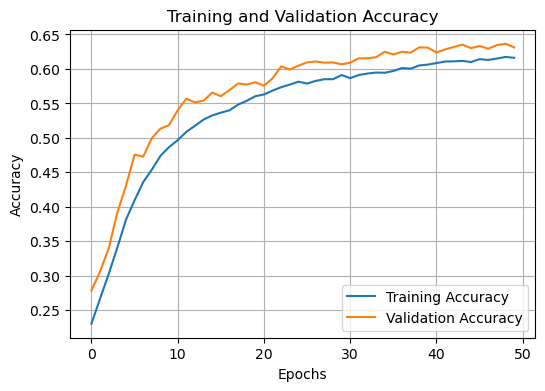

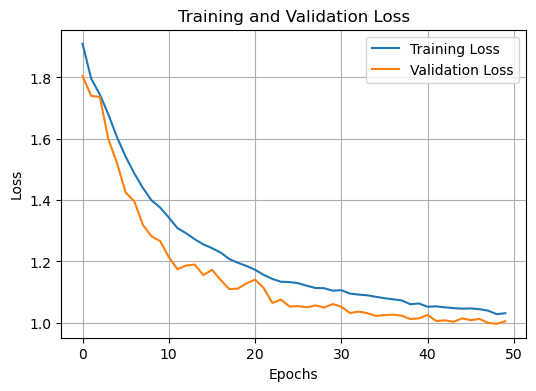

In [6]:
## 8. Training & Validation Curves
import matplotlib.pyplot as plt
plt.figure(figsize=(6,4))
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.title("Training and Validation Accuracy")
plt.legend()
plt.grid(True)
plt.show()

plt.figure(figsize=(6,4))
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.title("Training and Validation Loss")
plt.legend()
plt.grid(True)
plt.show()

In [7]:
## 9. Test Evaluation

test_loss, test_accuracy = model.evaluate(test)
print(f"Test Accuracy: {test_accuracy:.4f}")
print(f"Test Loss: {test_loss:.4f}")

225/225 ━━━━━━━━━━━━━━━━━━━━ 12s 52ms/step - accuracy: 0.6365 - loss: 0.9967
Test Accuracy: 0.6365
Test Loss: 0.9967


225/225 ━━━━━━━━━━━━━━━━━━━━ 9s 37ms/step


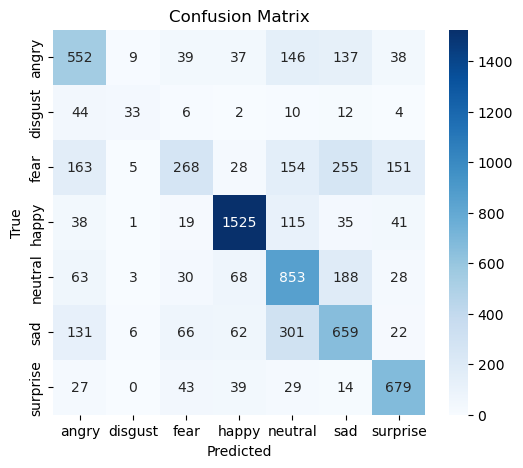

              precision    recall  f1-score   support

       angry       0.54      0.58      0.56       958
     disgust       0.58      0.30      0.39       111
        fear       0.57      0.26      0.36      1024
       happy       0.87      0.86      0.86      1774
     neutral       0.53      0.69      0.60      1233
         sad       0.51      0.53      0.52      1247
    surprise       0.71      0.82      0.76       831

    accuracy                           0.64      7178
   macro avg       0.61      0.58      0.58      7178
weighted avg       0.64      0.64      0.63      7178



In [8]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, classification_report, roc_curve, auc

# 1. Ensure test generator does NOT shuffle (crucial for matching predictions to true labels)
test.reset()

# 2. Get predictions across the entire test set
preds = model.predict(test)
y_pred = np.argmax(preds, axis=1)

# 3. Extract true class indices directly from the generator
y_true = test.classes

# 4. Extract class names from the generator
class_names = list(test.class_indices.keys())

# 5. Plot Confusion Matrix
cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=class_names, yticklabels=class_names)
plt.xlabel("Predicted")
plt.ylabel("True")
plt.title("Confusion Matrix")
plt.show()

# 6. Classification Report
print(classification_report(y_true, y_pred, target_names=class_names))

225/225 ━━━━━━━━━━━━━━━━━━━━ 8s 37ms/step


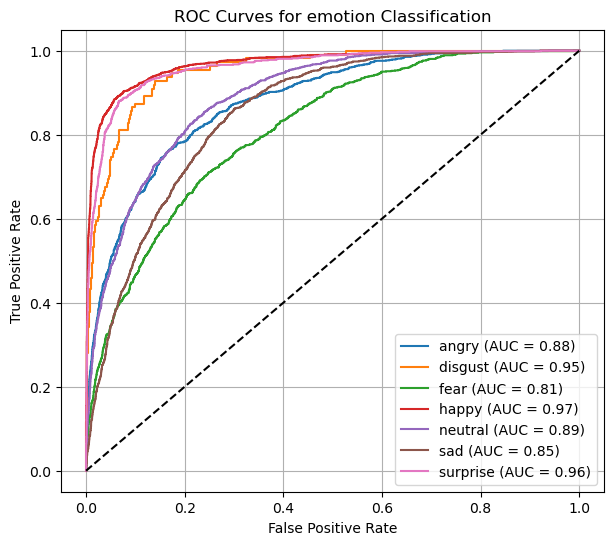

In [9]:
from sklearn.metrics import roc_curve, auc
from sklearn.preprocessing import label_binarize

# 1. Binarize labels using all available classes dynamically
n_classes = len(class_names)
y_true_bin = label_binarize(y_true, classes=list(range(n_classes)))

# 2. Ensure test generator is reset before predicting probabilities
test.reset()
y_score = model.predict(test)

plt.figure(figsize=(7, 6))

# 3. Compute ROC curve and AUC for each class
for i, cls in enumerate(class_names):
    fpr, tpr, _ = roc_curve(y_true_bin[:, i], y_score[:, i])
    roc_auc = auc(fpr, tpr)
    plt.plot(fpr, tpr, label=f"{cls} (AUC = {roc_auc:.2f})")

plt.plot([0, 1], [0, 1], 'k--')
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curves for emotion Classification")
plt.legend(loc="lower right")
plt.grid(True)
plt.show()

In [10]:
# save model
model.save("emotion_detector.keras")